# Насколько устойчиво сравнение моделей

## 1. Три проверки

Сравниваем фиксированные модели 08 с частотой аэропорта из train, описываем
результат при одинаковом числе положительных прогнозов и проверяем интервалы
при более длинных временных блоках. Нового обучения нет.

Протокол: `reports/research_extension_protocol.md`. Этот анализ введен после
просмотра test: результаты исследовательские. Порог F1 из 08 не заменяем.
Пороги дополнительных сценариев определяем только по scores validation.
Бюджеты 0.1%, 0.5%, 1%, 5% являются исследовательскими, не авиационными нормами.
Ориентир аэропорта не доказывает причинную роль аэропорта или эксплуатационную
доступность конечного пункта.

In [1]:
from pathlib import Path
import os,json,hashlib,math
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from scipy.special import expit
from sklearn.metrics import average_precision_score,roc_auc_score,brier_score_loss
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd().resolve()
while not (ROOT/'reports/baseline_frozen_selection.json').exists():
    if ROOT==ROOT.parent:raise FileNotFoundError('Нет результатов 08')
    ROOT=ROOT.parent
R=ROOT/'reports';F=ROOT/'figures';LOCAL=ROOT/'data'
DATA_ROOT=Path(os.environ.get('SAMPLE_SELECTION_DATA_ROOT',ROOT.parents[1]))
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as stream:
        for b in iter(lambda:stream.read(8*1024*1024),b''):h.update(b)
    return h.hexdigest()
entry=next(e for e in json.loads((R/'verification.json').read_text(encoding='utf-8'))['inputs'] if e['stage']=='final')
DATA=DATA_ROOT/entry['file'].replace(chr(92),'/')
if not DATA.exists():DATA=LOCAL/'06_05_cases_excluded.parquet'
SPLIT=LOCAL/'06_candidate_split_labels.parquet';PRED=LOCAL/'08_test_predictions.parquet'
FREEZE=R/'baseline_frozen_selection.json';digest_pred=sha(PRED);digest_freeze=sha(FREEZE)
selection=json.loads(FREEZE.read_text(encoding='utf-8'))
plan=json.loads((R/'preparation_plan.json').read_text(encoding='utf-8'))
assert sha(DATA)==entry['sha256'] and sha(SPLIT)==plan['split_file_sha256']
vocab=json.loads((R/'preparation_train_vocabulary.json').read_text(encoding='utf-8'))['vocabulary']
scaler=json.loads((R/'preparation_numeric_scaler.json').read_text(encoding='utf-8'))['parameters']
labels=pq.read_table(SPLIT).to_pandas();pred=pq.read_table(PRED).to_pandas()
assert np.array_equal(labels.source_row,np.arange(len(labels)))
cats=['airport','typecode','icaoaircrafttype'];names=[]
for f in cats:names += [f+':'+v for v in vocab[f]]+[f+':<MISSING>',f+':<UNSEEN>']
numeric=['lat_z','lon_z','utc_time_sin','utc_time_cos']+[f'utc_weekday:{i}' for i in range(7)]
names+=numeric
model_paths={m:LOCAL/'baseline_models'/f'{m}_C{v["C"]:g}.json' for m,v in selection['chosen'].items()}
digests_models={m:sha(p) for m,p in model_paths.items()}
coefficients={}
for m,p in model_paths.items():
    fit=json.loads(p.read_text(encoding='utf-8'));assert fit['signature']==selection['signature']
    fields=names if m=='geometry_aircraft' else [v for v in names if v.startswith('airport:') or v in numeric]
    assert len(fields)==len(fit['coef'])
    coefficients[m]=(dict(zip(fields,fit['coef'])),fit['intercept'])
def predict(d,m):
    weights,intercept=coefficients[m];z=np.full(len(d),intercept)
    for f in cats:
        if m=='geometry' and f!='airport':continue
        category=d[f].where(d[f].notna()&d[f].ne('').fillna(False),'<MISSING>')
        assert not set(vocab[f])&{'<MISSING>','<UNSEEN>'}
        mapping={v:weights[f+':'+v] for v in vocab[f]}
        mapping['<MISSING>']=weights[f+':<MISSING>']
        z+=category.map(mapping).fillna(weights[f+':<UNSEEN>']).to_numpy()
    t=d.C40_CROSS_TIME;phase=2*np.pi*(t.dt.hour*3600+t.dt.minute*60+t.dt.second+t.dt.microsecond/1e6).to_numpy()/86400
    z+=weights['lat_z']*(d.C40_CROSS_LAT.to_numpy()-scaler['C40_CROSS_LAT']['mean'])/scaler['C40_CROSS_LAT']['scale']
    z+=weights['lon_z']*(d.C40_CROSS_LON.to_numpy()-scaler['C40_CROSS_LON']['mean'])/scaler['C40_CROSS_LON']['scale']
    z+=weights['utc_time_sin']*np.sin(phase)+weights['utc_time_cos']*np.cos(phase)
    z+=np.array([weights[f'utc_weekday:{i}'] for i in t.dt.dayofweek])
    return expit(z)
chunks=[];offset=0;maximum_error={m:0. for m in coefficients}
for batch in pq.ParquetFile(DATA).iter_batches(batch_size=200000,columns=cats+['C40_CROSS_TIME','C40_CROSS_LAT','C40_CROSS_LON','GoA']):
    d=batch.to_pandas();status=labels.split.iloc[offset:offset+len(d)].to_numpy()
    for part in ['validation','test']:
        mask=status==part;a=d[mask].copy()
        if not len(a):continue
        a['source_row']=np.arange(offset,offset+len(d))[mask]
        for model in coefficients:a[model]=predict(a,model)
        if part=='validation':chunks.append(a[['airport','GoA','source_row']+list(coefficients)])
        else:
            old=pred.set_index('source_row').loc[a.source_row]
            assert np.array_equal(old.GoA,a.GoA) and np.array_equal(old.airport,a.airport)
            for m in coefficients:maximum_error[m]=max(maximum_error[m],float(np.max(np.abs(old[m].to_numpy()-a[m].to_numpy()))))
    offset+=len(d)
assert max(maximum_error.values())<1e-12 and offset==entry['rows']
valid=pd.concat(chunks,ignore_index=True);del chunks,labels
train=pd.read_csv(R/'protocol_airport_coverage.csv').query('split=="train"').set_index('airport')
assert train.rows.sum()==plan['model_plan']['fit_rows'] if 'fit_rows' in plan['model_plan'] else train.rows.sum()>0
airport_prior=(train.goa/train.rows).to_dict();global_prior=float(train.goa.sum()/train.rows.sum())
assert np.isclose(global_prior,selection['constant_probability'])
valid['airport_prior']=valid.airport.map(airport_prior).fillna(global_prior)
pred['airport_prior']=pred.airport.map(airport_prior).fillna(global_prior)
models=['airport_prior','geometry','geometry_aircraft'];colors={'airport_prior':'#546E63','geometry':'#00897B','geometry_aircraft':'#D65A4A'}
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']:plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()
summary=[]
for part,d in [('validation',valid),('test',pred)]:
    y=d.GoA.to_numpy(dtype=np.int8)
    for m in models:
        p=d[m].to_numpy();summary.append({'split':part,'model':m,'rows':len(d),'goa':int(y.sum()),
          'AP':average_precision_score(y,p),'ROC_AUC':roc_auc_score(y,p),'Brier':brier_score_loss(y,p)})
summary=pd.DataFrame(summary);summary.to_csv(R/'comparison_reference_metrics.csv',index=False);display(summary)

,split,model,rows,goa,AP,ROC_AUC,Brier
0,validation,airport_prior,1619847,4984,0.003672,0.565240,0.003067
1,validation,geometry,1619847,4984,0.003732,0.569868,0.003067
2,validation,geometry_aircraft,1619847,4984,0.004144,0.585495,0.003067
3,test,airport_prior,546577,1739,0.003808,0.563901,0.003171
4,test,geometry,546577,1739,0.003759,0.562344,0.003171
5,test,geometry_aircraft,546577,1739,0.003980,0.572297,0.003171


## 2. Пороги из validation и одинаковый ранговый бюджет

Числовой порог из validation не гарантирует ту же долю положительных прогнозов
в будущем. Поэтому публикуем реальную долю test рядом с заданным бюджетом.

Отдельный top-k аудит задает одинаковое число позиций test для всех моделей.
На границе равных scores используем одинаковый дробный вес для всех записей
с этим score, без сортировки по метке или идентификатору. TP/FP здесь ожидаемые
числа при случайном выборе внутри ties, а не целочисленная матрица ошибок.
Этот аудит описывает ранжирование уже наблюдаемой группы, не оперативную политику.

,model,budget_validation,threshold,validation_alert_rate,test_alert_rate,tp,fp,fn,recall,precision
0,airport_prior,0.00100,0.00366,0.00000,0.00000,0,0,1739,0.00000,nan
1,airport_prior,0.00500,0.00366,0.00000,0.00000,0,0,1739,0.00000,nan
2,airport_prior,0.01000,0.00366,0.00000,0.00000,0,0,1739,0.00000,nan
3,airport_prior,0.05000,0.00366,0.00000,0.00000,0,0,1739,0.00000,nan
4,geometry,0.00100,0.00399,0.00100,0.00148,2,806,1737,0.00115,0.00248
5,geometry,0.00500,0.00393,0.00500,0.00718,14,3912,1725,0.00805,0.00357
6,geometry,0.01000,0.00387,0.01000,0.01404,23,7653,1716,0.01323,0.00300
7,geometry,0.05000,0.00373,0.05000,0.06758,147,36788,1592,0.08453,0.00398
8,geometry_aircraft,0.00100,0.00662,0.00100,0.00065,2,355,1737,0.00115,0.00560
9,geometry_aircraft,0.00500,0.00564,0.00500,0.00564,10,3070,1729,0.00575,0.00325


,model,budget_test,positions,expected_tp,expected_fp,recall,precision,boundary_tie_rows,boundary_tie_weight
0,airport_prior,0.00100,546,2.30904,543.69096,0.00133,0.00423,72121,0.00757
1,airport_prior,0.00500,2732,11.55364,2720.44636,0.00664,0.00423,72121,0.03788
2,airport_prior,0.01000,5465,23.11151,5441.88849,0.01329,0.00423,72121,0.07578
3,airport_prior,0.05000,27328,115.57022,27212.42978,0.06646,0.00423,72121,0.37892
4,geometry,0.00100,546,1.00000,545.00000,0.00058,0.00183,1,1.00000
5,geometry,0.00500,2732,9.00000,2723.00000,0.00518,0.00329,1,1.00000
6,geometry,0.01000,5465,18.00000,5447.00000,0.01035,0.00329,1,1.00000
7,geometry,0.05000,27328,108.00000,27220.00000,0.06210,0.00395,1,1.00000
8,geometry_aircraft,0.00100,546,3.00000,543.00000,0.00173,0.00549,1,1.00000
9,geometry_aircraft,0.00500,2732,10.00000,2722.00000,0.00575,0.00366,1,1.00000


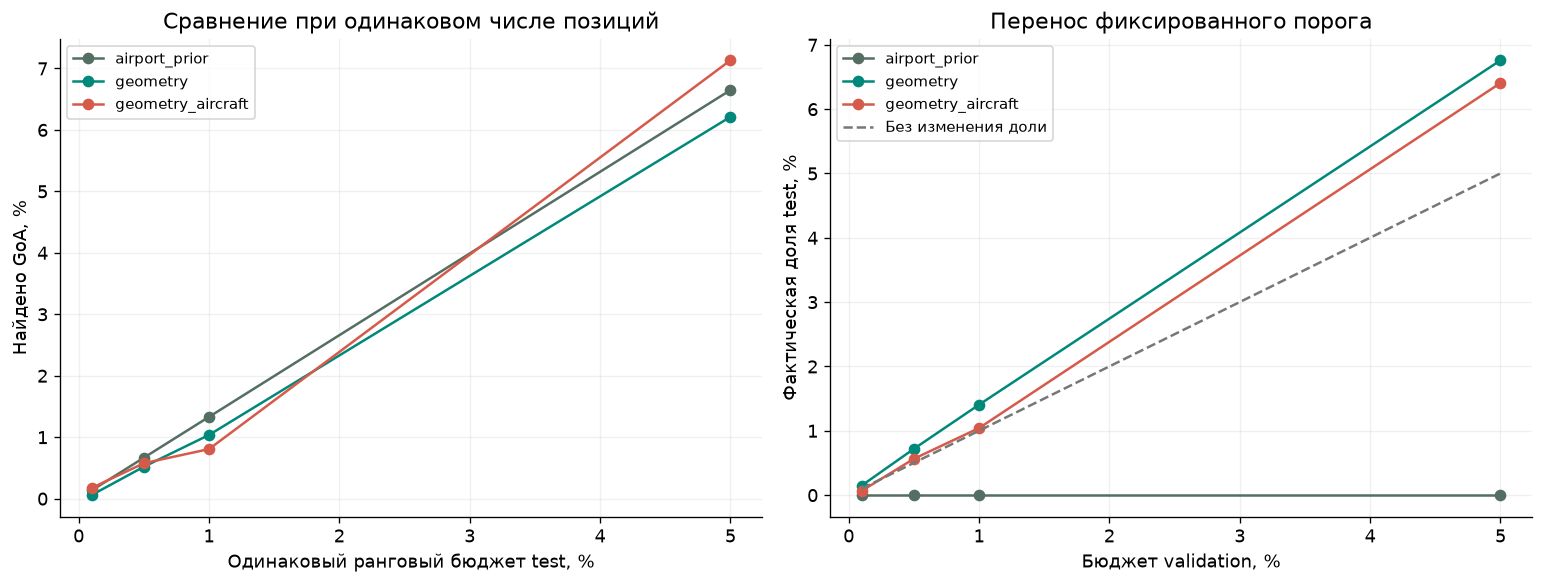

In [2]:
budgets=[.001,.005,.01,.05]
def threshold_for_budget(p,budget):
    values,counts=np.unique(p,return_counts=True);values=values[::-1];counts=counts[::-1]
    cumulative=np.cumsum(counts);k=int(np.floor(len(p)*budget));ok=np.flatnonzero(cumulative<=k)
    return float(values[ok[-1]]) if len(ok) else float(np.nextafter(values[0],np.inf))
frozen=[]
for m in models:
    for b in budgets:
        t=threshold_for_budget(valid[m].to_numpy(),b)
        assert (valid[m]>=t).mean()<=b
        frozen.append({'model':m,'budget_validation':b,'threshold':t,'validation_alert_rate':float((valid[m]>=t).mean())})
frozen=pd.DataFrame(frozen)
(R/'comparison_budget_thresholds.json').write_text(json.dumps({'status':'exploratory_after_test_inspection',
 'selection_uses_outcomes':False,'selection_split':'validation','thresholds':frozen.to_dict('records')},indent=2),encoding='utf-8')
threshold_results=[];ranking=[];y=pred.GoA.to_numpy(dtype=np.int8)
for row in frozen.itertuples():
    p=pred[row.model].to_numpy();a=p>=row.threshold
    tp=int((a&(y==1)).sum());fp=int((a&(y==0)).sum())
    threshold_results.append({'model':row.model,'budget_validation':row.budget_validation,'threshold':row.threshold,
      'validation_alert_rate':row.validation_alert_rate,'test_alert_rate':float(a.mean()),'tp':tp,'fp':fp,
      'fn':int(y.sum())-tp,'recall':tp/int(y.sum()),'precision':tp/(tp+fp) if tp+fp else np.nan})
    k=int(np.floor(len(y)*row.budget_validation));cut=np.partition(p,len(p)-k)[len(p)-k]
    above=p>cut;tie=p==cut;fraction=(k-int(above.sum()))/int(tie.sum())
    expected_tp=float(y[above].sum()+fraction*y[tie].sum())
    assert 0<=fraction<=1 and np.isclose(above.sum()+fraction*tie.sum(),k)
    ranking.append({'model':row.model,'budget_test':row.budget_validation,'positions':k,
      'expected_tp':expected_tp,'expected_fp':k-expected_tp,'recall':expected_tp/int(y.sum()),
      'precision':expected_tp/k,'boundary_tie_rows':int(tie.sum()),'boundary_tie_weight':fraction})
threshold_results=pd.DataFrame(threshold_results);ranking=pd.DataFrame(ranking)
threshold_results.to_csv(R/'comparison_budget_metrics.csv',index=False);ranking.to_csv(R/'comparison_equal_budget.csv',index=False)
display(threshold_results.style.format(precision=5));display(ranking.style.format(precision=5))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for m in models:
    q=ranking[ranking.model.eq(m)]
    axes[0].plot(100*q.budget_test,100*q.recall,'o-',color=colors[m],label=m)
    q=threshold_results[threshold_results.model.eq(m)]
    axes[1].plot(100*q.budget_validation,100*q.test_alert_rate,'o-',color=colors[m],label=m)
axes[0].set(xlabel='Одинаковый ранговый бюджет test, %',ylabel='Найдено GoA, %',title='Сравнение при одинаковом числе позиций')
axes[1].plot([.1,5],[.1,5],'--',color='#777777',label='Без изменения доли')
axes[1].set(xlabel='Бюджет validation, %',ylabel='Фактическая доля test, %',title='Перенос фиксированного порога')
for ax in axes:ax.legend(fontsize=9)
save('35_equal_budget_comparison')

## 3. Чувствительность интервалов к зависимости во времени

Используем 1000 парных повторов для каждой длины блока. Для 2/4 недель
выбираем начала блоков с возвращением, циклически берем соседние недели,
обрезаем последовательность до исходного числа недель. Круговая граница
является допущением метода. Модели не переобучаются; интервалы не учитывают
неопределенность обучения, зависимость одного борта и все виды дрейфа.

Выполнено 1000 повторов: блок 1 недель


Выполнено 1000 повторов: блок 2 недель


Выполнено 1000 повторов: блок 4 недель


,block_weeks,comparison,metric,estimate,lower,upper,valid_replicates,observed_weeks
0,1,geometry_aircraft - geometry,AP,0.0002209,0.0000273,0.0004607,1000,23
1,1,geometry - airport_prior,AP,-0.0000491,-0.0002148,0.0001300,1000,23
2,1,geometry_aircraft - airport_prior,AP,0.0001718,0.0000138,0.0004311,1000,23
3,1,geometry_aircraft - geometry,ROC_AUC,0.0099532,0.0021522,0.0181860,1000,23
4,1,geometry - airport_prior,ROC_AUC,-0.0015571,-0.0094443,0.0060794,1000,23
5,1,geometry_aircraft - airport_prior,ROC_AUC,0.0083961,0.0008660,0.0162054,1000,23
6,2,geometry_aircraft - geometry,AP,0.0002209,0.0000308,0.0004737,1000,23
7,2,geometry - airport_prior,AP,-0.0000491,-0.0002103,0.0001563,1000,23
8,2,geometry_aircraft - airport_prior,AP,0.0001718,0.0000262,0.0004205,1000,23
9,2,geometry_aircraft - geometry,ROC_AUC,0.0099532,0.0016771,0.0184087,1000,23


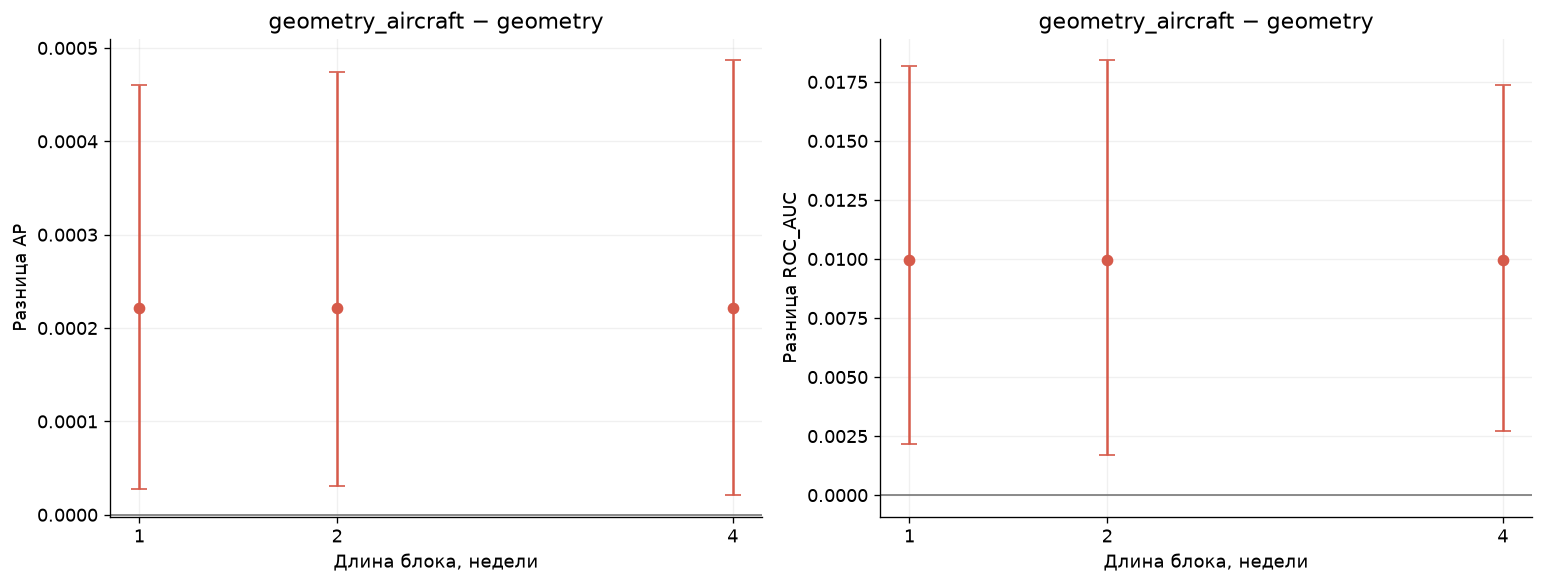

In [3]:
def cache(y,p):
    order=np.argsort(-p,kind='stable');score=p[order]
    ends=np.r_[np.flatnonzero(score[1:]!=score[:-1]),len(score)-1]
    return order,ends,y[order]
def weighted_metrics(c,w):
    order,ends,ys=c;v=w[order];cp=np.cumsum(v*ys)[ends];cn=np.cumsum(v*(1-ys))[ends]
    dp=np.diff(np.r_[0,cp]);dn=np.diff(np.r_[0,cn]);P=cp[-1];N=cn[-1]
    if P<=0 or N<=0:return np.nan,np.nan
    precision=np.divide(cp,cp+cn,out=np.zeros_like(cp),where=cp+cn>0)
    return float(np.sum(dp*precision)/P),float(np.sum(dn*(cp-dp/2))/(P*N))
caches={m:cache(y,pred[m].to_numpy()) for m in models}
for m,c in caches.items():
    assert np.allclose(weighted_metrics(c,np.ones(len(y))),
      [average_precision_score(y,pred[m]),roc_auc_score(y,pred[m])])
toy_y=np.array([1,0,1,0,1]);toy_p=np.array([.5,.5,.2,.1,.2]);toy_w=np.array([1.,2.,0.,1.,3.])
assert np.allclose(weighted_metrics(cache(toy_y,toy_p),toy_w),
 [average_precision_score(toy_y,toy_p,sample_weight=toy_w),roc_auc_score(toy_y,toy_p,sample_weight=toy_w)])
week=pred.C40_CROSS_TIME.dt.floor('D')-pd.to_timedelta(pred.C40_CROSS_TIME.dt.dayofweek,unit='D')
weeks=sorted(week.unique());week_index=pd.Categorical(week,categories=weeks,ordered=True).codes
assert all(pd.Timestamp(weeks[i+1])-pd.Timestamp(weeks[i])==pd.Timedelta(days=7) for i in range(len(weeks)-1))
rows=[]
for length in [1,2,4]:
    rng=np.random.default_rng(42)
    for replicate in range(1000):
        starts=rng.integers(0,len(weeks),size=math.ceil(len(weeks)/length))
        draw=((starts[:,None]+np.arange(length))%len(weeks)).ravel()[:len(weeks)]
        counts=np.bincount(draw,minlength=len(weeks));weights=counts[week_index].astype(float)
        for m,c in caches.items():
            ap,auc=weighted_metrics(c,weights)
            rows.append({'block_weeks':length,'replicate':replicate,'model':m,'AP':ap,'ROC_AUC':auc})
    print(f'Выполнено 1000 повторов: блок {length} недель',flush=True)
boot=pd.DataFrame(rows);boot.to_csv(R/'comparison_block_bootstrap.csv',index=False)
intervals=[]
for length,g in boot.groupby('block_weeks'):
    for metric in ['AP','ROC_AUC']:
        p=g.pivot(index='replicate',columns='model',values=metric)
        for a,b in [('geometry_aircraft','geometry'),('geometry','airport_prior'),('geometry_aircraft','airport_prior')]:
            delta=(p[a]-p[b]).dropna();original=summary[summary.split.eq('test')].set_index('model')
            intervals.append({'block_weeks':length,'comparison':a+' - '+b,'metric':metric,
              'estimate':float(original.loc[a,metric]-original.loc[b,metric]),
              'lower':float(delta.quantile(.025)),'upper':float(delta.quantile(.975)),
              'valid_replicates':len(delta),'observed_weeks':len(weeks)})
intervals=pd.DataFrame(intervals);intervals.to_csv(R/'comparison_block_intervals.csv',index=False)
display(intervals.style.format(precision=7))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,metric in zip(axes,['AP','ROC_AUC']):
    q=intervals[intervals.metric.eq(metric)&intervals.comparison.eq('geometry_aircraft - geometry')]
    for row in q.itertuples():
        ax.errorbar(row.block_weeks,row.estimate,yerr=[[row.estimate-row.lower],[row.upper-row.estimate]],
                    fmt='o',capsize=5,color='#D65A4A')
    ax.axhline(0,color='#777777',lw=1);ax.set(xticks=[1,2,4],xlabel='Длина блока, недели',
      ylabel='Разница '+metric,title='geometry_aircraft − geometry')
    ax.ticklabel_format(axis='y',style='plain',useOffset=False)
save('36_block_sensitivity')

## 4. Что проверено

Дополнительный ориентир и бюджеты не выбираются по test. Это проверка устойчивости
интерпретации, а не новый конкурс моделей. Все сценарии публикуются.

In [4]:
assert sha(DATA)==entry['sha256'] and sha(SPLIT)==plan['split_file_sha256']
assert sha(PRED)==digest_pred and sha(FREEZE)==digest_freeze
assert all(sha(model_paths[m])==h for m,h in digests_models.items())
assert len(boot)==9000 and boot.groupby(['block_weeks','replicate']).model.nunique().eq(3).all()
verification={'status':'exploratory_after_test_inspection','input_sha256':entry['sha256'],
 'prediction_sha256':digest_pred,'selection_sha256':digest_freeze,
 'models_unchanged':True,'inputs_unchanged':True,'retraining_performed':False,
 'test_prediction_maximum_error':maximum_error,'coefficient_replay_passed':True,
 'airport_prior_fit_split':'train','budget_selection_split':'validation',
 'budget_selection_uses_labels':False,'test_ranking_is_retrospective':True,
 'weighted_metric_parity_passed':True,'bootstrap_replicates_per_length':1000,'block_lengths_weeks':[1,2,4]}
(R/'comparison_verification.json').write_text(json.dumps(verification,indent=2),encoding='utf-8')
text=f"""# Проверка сравнения моделей

Ориентиры:
{summary.to_string(index=False)}

Одинаковый бюджет test:
{ranking.to_string(index=False)}

Чувствительность парных интервалов:
{intervals.to_string(index=False)}

Старые модели, прогнозы и F1-пороги не менялись. Обучения нет.
Дополнительные числовые пороги определены по scores validation без меток.
Ранговый бюджет test — описательная оценка, не заранее доступный числовой порог.
Ориентир аэропорта и новые сравнения введены после просмотра test.
"""
(R/'comparison_findings.md').write_text(text,encoding='utf-8');display(Markdown(text))

# Проверка сравнения моделей

Ориентиры:
     split             model    rows  goa       AP  ROC_AUC    Brier
validation     airport_prior 1619847 4984 0.003672 0.565240 0.003067
validation          geometry 1619847 4984 0.003732 0.569868 0.003067
validation geometry_aircraft 1619847 4984 0.004144 0.585495 0.003067
      test     airport_prior  546577 1739 0.003808 0.563901 0.003171
      test          geometry  546577 1739 0.003759 0.562344 0.003171
      test geometry_aircraft  546577 1739 0.003980 0.572297 0.003171

Одинаковый бюджет test:
            model  budget_test  positions  expected_tp  expected_fp   recall  precision  boundary_tie_rows  boundary_tie_weight
    airport_prior        0.001        546     2.309036   543.690964 0.001328   0.004229              72121             0.007571
    airport_prior        0.005       2732    11.553639  2720.446361 0.006644   0.004229              72121             0.037881
    airport_prior        0.010       5465    23.111507  5441.888493 0.013290   0.004229              72121             0.075775
    airport_prior        0.050      27328   115.570222 27212.429778 0.066458   0.004229              72121             0.378919
         geometry        0.001        546     1.000000   545.000000 0.000575   0.001832                  1             1.000000
         geometry        0.005       2732     9.000000  2723.000000 0.005175   0.003294                  1             1.000000
         geometry        0.010       5465    18.000000  5447.000000 0.010351   0.003294                  1             1.000000
         geometry        0.050      27328   108.000000 27220.000000 0.062105   0.003952                  1             1.000000
geometry_aircraft        0.001        546     3.000000   543.000000 0.001725   0.005495                  1             1.000000
geometry_aircraft        0.005       2732    10.000000  2722.000000 0.005750   0.003660                  1             1.000000
geometry_aircraft        0.010       5465    14.000000  5451.000000 0.008051   0.002562                  1             1.000000
geometry_aircraft        0.050      27328   124.000000 27204.000000 0.071305   0.004537                  1             1.000000

Чувствительность парных интервалов:
 block_weeks                        comparison  metric  estimate     lower    upper  valid_replicates  observed_weeks
           1      geometry_aircraft - geometry      AP  0.000221  0.000027 0.000461              1000              23
           1          geometry - airport_prior      AP -0.000049 -0.000215 0.000130              1000              23
           1 geometry_aircraft - airport_prior      AP  0.000172  0.000014 0.000431              1000              23
           1      geometry_aircraft - geometry ROC_AUC  0.009953  0.002152 0.018186              1000              23
           1          geometry - airport_prior ROC_AUC -0.001557 -0.009444 0.006079              1000              23
           1 geometry_aircraft - airport_prior ROC_AUC  0.008396  0.000866 0.016205              1000              23
           2      geometry_aircraft - geometry      AP  0.000221  0.000031 0.000474              1000              23
           2          geometry - airport_prior      AP -0.000049 -0.000210 0.000156              1000              23
           2 geometry_aircraft - airport_prior      AP  0.000172  0.000026 0.000421              1000              23
           2      geometry_aircraft - geometry ROC_AUC  0.009953  0.001677 0.018409              1000              23
           2          geometry - airport_prior ROC_AUC -0.001557 -0.008822 0.007986              1000              23
           2 geometry_aircraft - airport_prior ROC_AUC  0.008396  0.002180 0.015363              1000              23
           4      geometry_aircraft - geometry      AP  0.000221  0.000021 0.000487              1000              23
           4          geometry - airport_prior      AP -0.000049 -0.000208 0.000142              1000              23
           4 geometry_aircraft - airport_prior      AP  0.000172  0.000053 0.000408              1000              23
           4      geometry_aircraft - geometry ROC_AUC  0.009953  0.002706 0.017350              1000              23
           4          geometry - airport_prior ROC_AUC -0.001557 -0.008973 0.007283              1000              23
           4 geometry_aircraft - airport_prior ROC_AUC  0.008396  0.003441 0.013885              1000              23

Старые модели, прогнозы и F1-пороги не менялись. Обучения нет.
Дополнительные числовые пороги определены по scores validation без меток.
Ранговый бюджет test — описательная оценка, не заранее доступный числовой порог.
Ориентир аэропорта и новые сравнения введены после просмотра test.
